# Task 3 — Instagram Engagement Analysis

Place the official Instagram/content-performance dataset in `data/raw/` with `instagram` or `engagement` in its filename.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
DATA = ROOT / "data" / "raw"
files = list(DATA.glob("*.csv")) + list(DATA.glob("*.xlsx")) + list(DATA.glob("*.json"))
print("Data files found:", [f.name for f in files])
print("Task 3 dataset: Instagram engagement analytics. Treat findings as specific to this dataset, not universal platform trends.")

def load_data(keywords):
    matches = [f for f in files if any(k in f.name.lower() for k in keywords)]
    if not matches:
        print("DATASET MISSING for:", keywords)
        return None
    f = matches[0]
    print("Loading:", f.name)
    if f.suffix.lower() == ".csv":
        return pd.read_csv(f)
    if f.suffix.lower() == ".xlsx":
        return pd.read_excel(f)
    return pd.read_json(f)

def overview(df):
    if df is None:
        return
    print("Shape:", df.shape)
    display(df.head())
    display(df.isna().sum().sort_values(ascending=False).head(20).to_frame("missing"))
    display(df.describe(include="all").T)

df = load_data(['instagram', 'engagement', 'social'])
overview(df)

Data files found: ['zomato.csv', 'loan_approval_dataset.csv', 'instagram_analytics.csv', 'business_sales_customers.csv']
Task 3 dataset: Instagram engagement analytics. Treat findings as specific to this dataset, not universal platform trends.
Loading: instagram_analytics.csv
Shape: (29999, 15)


,post_id,upload_date,media_type,likes,comments,shares,saves,reach,impressions,caption_length,hashtags_count,followers_gained,traffic_source,engagement_rate,content_category
0,IG0000001,2024-11-30 09:25:22.954916,Reel,31627,7559,4530,6393,615036,1007750,1340,3,899,Home Feed,4.97,Technology
1,IG0000002,2025-08-15 09:25:22.954916,Photo,63206,3490,1680,6809,1237071,1345900,1351,20,805,Hashtags,5.59,Fitness
2,IG0000003,2025-09-11 09:25:22.954916,Reel,94373,3727,1761,8367,1127470,1305369,242,24,758,Reels Feed,8.29,Beauty
3,IG0000004,2025-09-18 09:25:22.954916,Reel,172053,7222,2875,9290,764030,897874,446,11,402,External,21.32,Music
4,IG0000005,2025-03-21 09:25:22.954916,Video,99646,2703,4444,9746,7004,495406,1905,8,155,Profile,23.52,Technology


,missing
post_id,0
upload_date,0
media_type,0
likes,0
comments,0
shares,0
saves,0
reach,0
impressions,0
caption_length,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
post_id,29999,29999,IG0000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
upload_date,29999,366,2025-02-26 09:25:22.954916,110,NaN,NaN,NaN,NaN,NaN,NaN,NaN
media_type,29999,4,Carousel,7526,NaN,NaN,NaN,NaN,NaN,NaN,NaN
likes,29999.0,NaN,NaN,NaN,99912.661789,57905.967401,7.0,49755.0,99580.0,150225.0,200000.0
comments,29999.0,NaN,NaN,NaN,5017.781426,2888.404881,0.0,2530.5,5042.0,7518.0,10000.0
shares,29999.0,NaN,NaN,NaN,2502.912564,1448.320395,0.0,1246.0,2498.0,3768.0,5000.0
saves,29999.0,NaN,NaN,NaN,7490.124637,4352.546949,0.0,3690.5,7483.0,11294.0,15000.0
reach,29999.0,NaN,NaN,NaN,996561.601953,577790.643192,165.0,493681.0,992181.0,1494798.0,1999865.0
impressions,29999.0,NaN,NaN,NaN,1246668.830961,597092.365465,5107.0,746958.5,1241026.0,1749263.5,2497940.0
caption_length,29999.0,NaN,NaN,NaN,1103.110904,635.991308,0.0,555.0,1100.0,1656.0,2200.0


## Engagement exploration

Detected columns: {'post_id': 'post_id', 'upload_date': 'upload_date', 'media_type': 'media_type', 'likes': 'likes', 'comments': 'comments', 'shares': 'shares', 'saves': 'saves', 'reach': 'reach', 'impressions': 'impressions', 'caption_length': 'caption_length', 'hashtags_count': 'hashtags_count', 'followers_gained': 'followers_gained', 'traffic_source': 'traffic_source', 'engagement_rate': 'engagement_rate', 'content_category': 'content_category'}

Summary for likes


count     29999.000000
mean      99912.661789
std       57905.967401
min           7.000000
25%       49755.000000
50%       99580.000000
75%      150225.000000
max      200000.000000
Name: likes, dtype: float64


Summary for comments


count    29999.000000
mean      5017.781426
std       2888.404881
min          0.000000
25%       2530.500000
50%       5042.000000
75%       7518.000000
max      10000.000000
Name: comments, dtype: float64


Summary for shares


...

upload_date
2025-02-26 09:25:22.954916    110
2025-02-27 09:25:22.954916    108
2025-06-23 09:25:22.954916    107
2025-02-18 09:25:22.954916    106
2025-06-14 09:25:22.954916    105
2025-01-27 09:25:22.954916    104
2025-03-19 09:25:22.954916    104
2025-05-08 09:25:22.954916    104
2025-07-01 09:25:22.954916    103
2025-05-03 09:25:22.954916    102
dtype: int64


Breakdown by media_type


media_type
Carousel    7526
Video       7523
Reel        7515
Photo       7435
dtype: int64


Breakdown by traffic_source


traffic_source
Home Feed     5069
Hashtags      5063
Reels Feed    5026
External      5005
Profile       4962
Explore       4874
dtype: int64

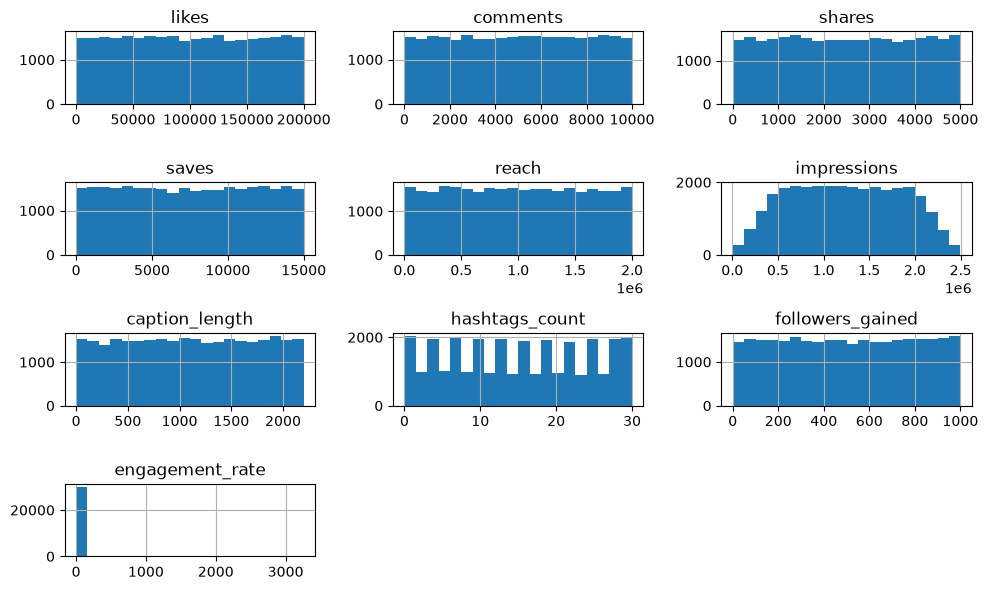

In [2]:
if df is not None:
    cols = {c.lower().replace(" ", "_"): c for c in df.columns}
    print("Detected columns:", cols)
    for key in ["likes", "comments", "shares", "reach", "impressions", "engagement_rate"]:
        actual = cols.get(key)
        if actual:
            print(f"\nSummary for {actual}")
            display(df[actual].describe())
    cat_cols = df.select_dtypes(include=["object", "category"]).columns
    for col in list(cat_cols)[:4]:
        print("\nBreakdown by", col)
        display(df.groupby(col, dropna=False).size().sort_values(ascending=False).head(10))
    numeric = df.select_dtypes(include="number")
    if not numeric.empty:
        numeric.hist(figsize=(10, 6), bins=20)
        plt.tight_layout()
        plt.show()
else:
    print("Dataset missing; do not invent engagement rates or best-performing post types.")

## Strategy and experiments

After analyzing the actual results, recommend content formats, posting cadence and calls to action. Track reach, saves, shares, profile visits and link clicks. Use controlled experiments rather than promising guaranteed growth.